In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "masbudget").is_dir() else Path.cwd().parent
os.chdir(ROOT)
sys.path[:0] = [str(ROOT), str(ROOT / "experiments")]
import pandas as pd
from IPython.display import Image, display
from lib import load, md_table
import plots
plots.style()
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 4)
%matplotlib inline

# E2 + E3 - Price of anarchy and arrival ordering

E2: centralized controllers vs. naive decentralized agents over a budget sweep (difficulty and oracle regimes). E3: five arrival policies x four agent behaviours. Notes in `experiments/E02_*.md`, `E03_*.md`.

In [2]:
s = load('e02_summary')
gap = s.pivot_table(index='policy', columns=['regime', 'tau'], values='gap_exp')
(100 * gap['difficulty']).round(1)

tau,0.00,0.02,0.05,0.10,0.20,0.35,0.50,0.75,1.00
policy,,,,,,,,,
Best model,86.1,85.6,81.7,72.5,60.0,38.3,16.7,0.0,0.0
Best model (round-robin),86.0,85.5,82.4,72.8,59.2,37.8,19.0,0.0,0.0
Cascade (verified),0.0,1.3,1.2,1.4,1.4,2.8,3.7,4.6,4.6
Cheapest model,0.0,2.1,3.5,5.7,9.8,14.8,15.6,16.4,16.4
MCKP (optimal),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Marginal ROI ratio,83.1,75.6,68.0,54.2,28.3,0.1,1.0,2.0,2.0
Predictive router,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Quasi-linear (repo lambda=0.5),86.1,85.6,81.7,72.5,60.0,38.3,16.7,0.0,0.0
"Shadow price (repo p0=0.1, a=1.5)",86.1,85.3,78.0,70.0,46.2,13.4,2.2,0.1,0.0


**Tragedy of the commons.** At moderate budget (tau = 0.2) agents that pick their best affordable model lose 60% of the optimal welfare; the repo-default utilities (lambda = 0.5, p0 = 0.1) are numerically identical to best-model because costs are ~1e-3 USD.

In [3]:
cols = ['policy', 'q_exp', 'q_real', 'gap_exp', 'task_starve', 'jain_real', 'fma_jobs', 'q_real_easy', 'q_real_medium', 'q_real_hard']
s[(s.regime == 'difficulty') & (s.tau == 0.2)][cols].sort_values('gap_exp')

,policy,q_exp,q_real,gap_exp,task_starve,jain_real,fma_jobs,q_real_easy,q_real_medium,q_real_hard
50,Predictive router,0.7383,0.7183,0.0000,0.0000,0.9638,NaN,1.0000,0.8448,0.3038
48,MCKP (optimal),0.7383,0.7255,0.0000,0.0000,0.9653,NaN,1.0000,0.8448,0.3258
54,Static equal quota,0.7279,0.7360,0.0142,0.0000,0.9624,NaN,1.0000,0.8970,0.3045
46,Cascade (verified),0.7279,0.7823,0.0142,0.0000,0.9740,NaN,1.0000,0.9948,0.3455
47,Cheapest model,0.6663,0.6760,0.0976,0.0000,0.9575,NaN,1.0000,0.9000,0.1197
49,Marginal ROI ratio,0.5296,0.5188,0.2827,0.3132,0.9157,inf,0.6826,0.5781,0.2923
52,"Shadow price (repo p0=0.1, a=1.5)",0.3970,0.3964,0.4624,0.4726,0.8719,inf,0.5196,0.4818,0.1846
45,Best model (round-robin),0.3009,0.3030,0.5924,0.6118,0.9229,inf,0.3806,0.3612,0.1652
51,Quasi-linear (repo lambda=0.5),0.2957,0.2974,0.5995,0.6213,0.8122,inf,0.3723,0.3604,0.1576
44,Best model,0.2957,0.2974,0.5995,0.6213,0.8122,inf,0.3723,0.3604,0.1576


Stratified by difficulty: naive agents starve **easy** tasks (q_real_easy = 0.37 vs 1.0 for MCKP) - the budget is gone before trivial tasks arrive. The verified cascade has a *higher realized* pass rate than MCKP (0.78 vs 0.73) because unit-test verification reveals information that q-hat does not have.

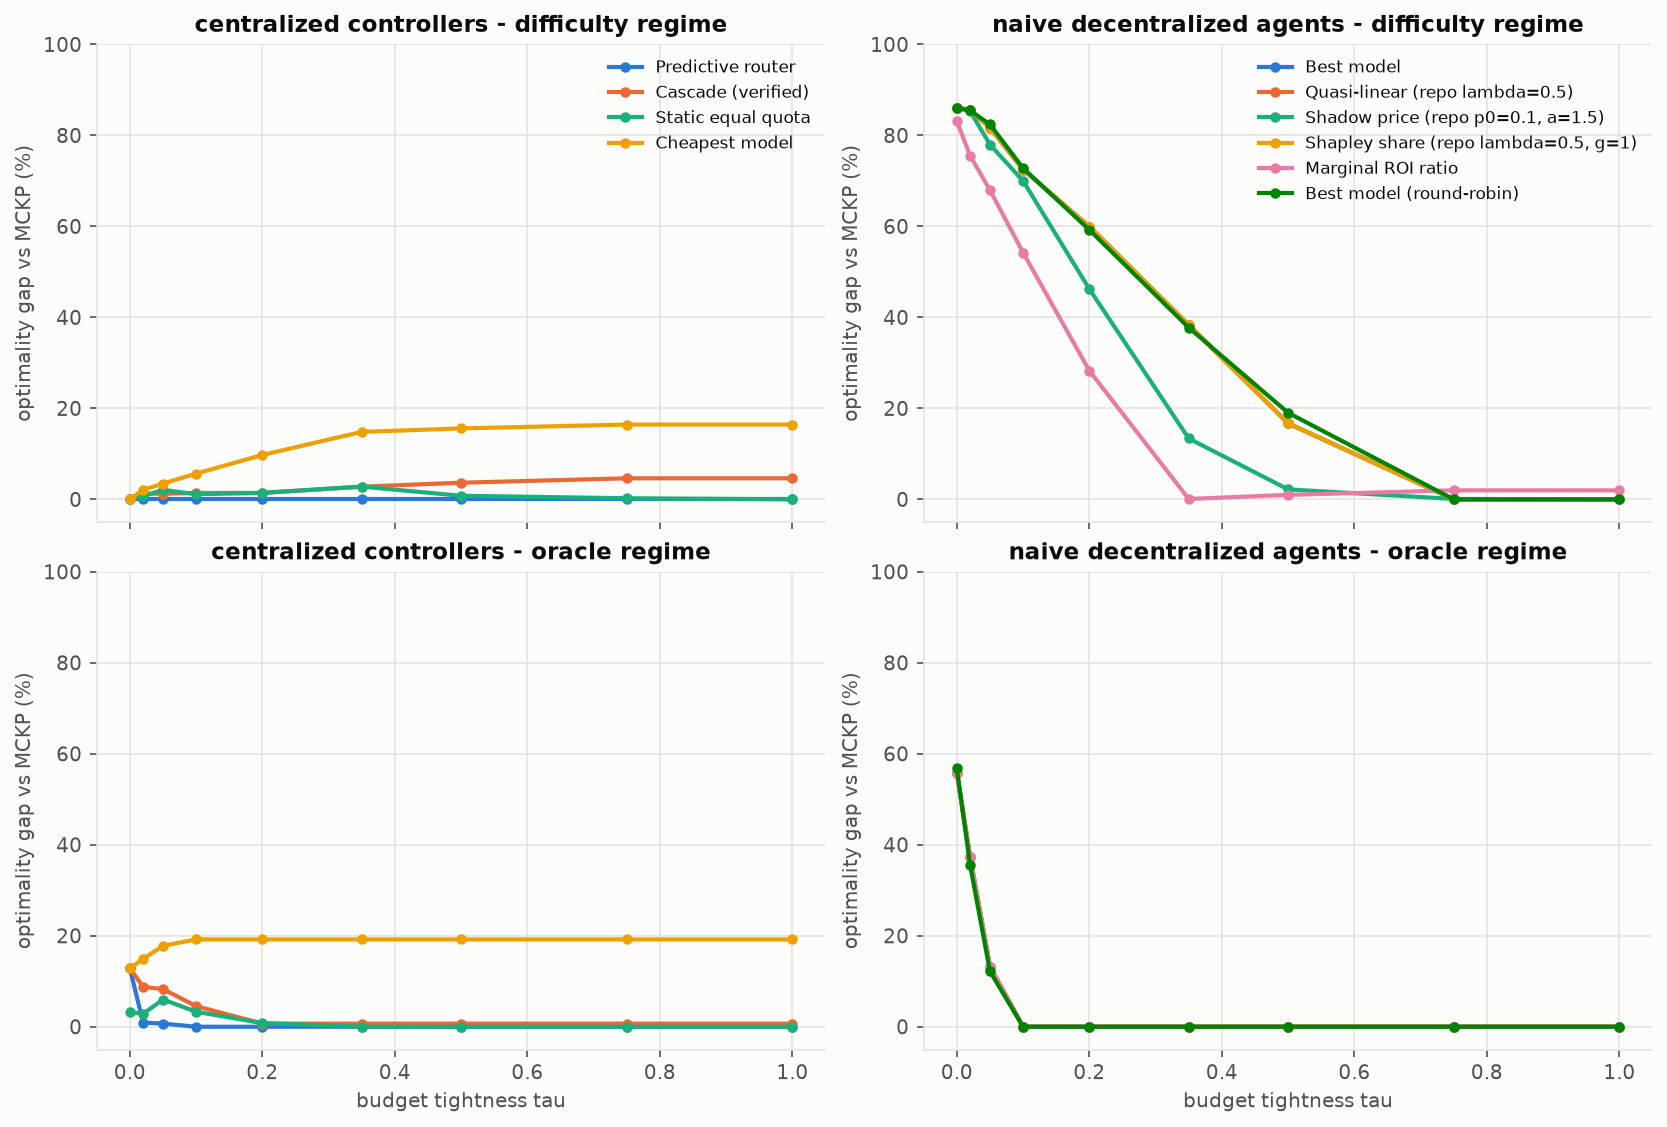

In [4]:
display(Image('experiments/figures/e02_price_of_anarchy.png'))

## E3 - Arrival ordering

In [5]:
a = load('e03_summary')
d = a[(a.tpa == 10) & (a.paradigm == 'decentralized')].copy()
d[['arrival', 'behaviour']] = d.policy.str.split(' \\| ', expand=True)
(100 * d.pivot_table(index=['tau', 'arrival'], columns='behaviour', values='gap_exp')).round(1)

behaviour                   best model  best model + reserve  pacing + reserve  quasi-linear (lambda=30)
tau  arrival                                                                                            
0.00 Easiest first                44.1                   0.0               0.0                       0.1
     Hardest first                96.2                   0.0               0.0                      13.6
     Marginal-ROI priority        84.0                   0.0               0.0                      13.6
     Random                       86.1                   0.0               0.0                       7.7
     Round-robin FCFS             86.0                   0.0               0.0                       8.0
0.05 Easiest first                31.1                   2.9               0.0                       2.1
     Hardest first                94.0                   1.1               1.2                       2.1
     Marginal-ROI priority        82.8                   2.9               0.7                       2.1
     Random                       81.7                   2.1               0.0                       2.1
     Round-robin FCFS             82.4                   2.0               0.0                       2.1
0.20 Easiest first                19.2                   7.7               1.5                       8.5
     Hardest first                86.4                   1.1               5.6                       8.5
     Marginal-ROI priority        67.5                   7.7               2.8                       8.5
     Random                       60.0                   4.4               0.1                       8.5
     Round-robin FCFS             59.2                   4.3               0.1                       8.5
0.50 Easiest first                 7.1                   5.7               5.7                      14.4
     Hardest first                49.3                   0.6               1.0                      14.4
     Marginal-ROI priority        48.0                   5.7               0.0                      14.4
     Random                       16.7                   3.1               0.1                      14.4
     Round-robin FCFS             19.0                   3.1               0.1                      14.4

Hardest-first is the *worst* order for greedy agents (86% gap: hard tasks drain the budget, easy tasks starve) and the *best* order with a reserve (1.1%). Pacing assumes spending can be spread over time, so it is best under uncoordinated (random / round-robin) arrival and loses a few points under sorted queues.

In [6]:
d[d.tau == 0.2].pivot_table(index='arrival', columns='behaviour', values='sw_sd').round(3)

behaviour,best model,best model + reserve,pacing + reserve,quasi-linear (lambda=30)
arrival,,,,
Easiest first,0.000,0.000,0.000,0.0
Hardest first,0.000,0.000,0.000,0.0
Marginal-ROI priority,0.000,0.000,0.000,0.0
Random,2.759,0.562,0.141,0.0
Round-robin FCFS,0.000,0.000,0.000,0.0


Order sensitivity (SD of social welfare across permutations, random arrival) falls from 2.76 to 0.14 with pacing + reserve.

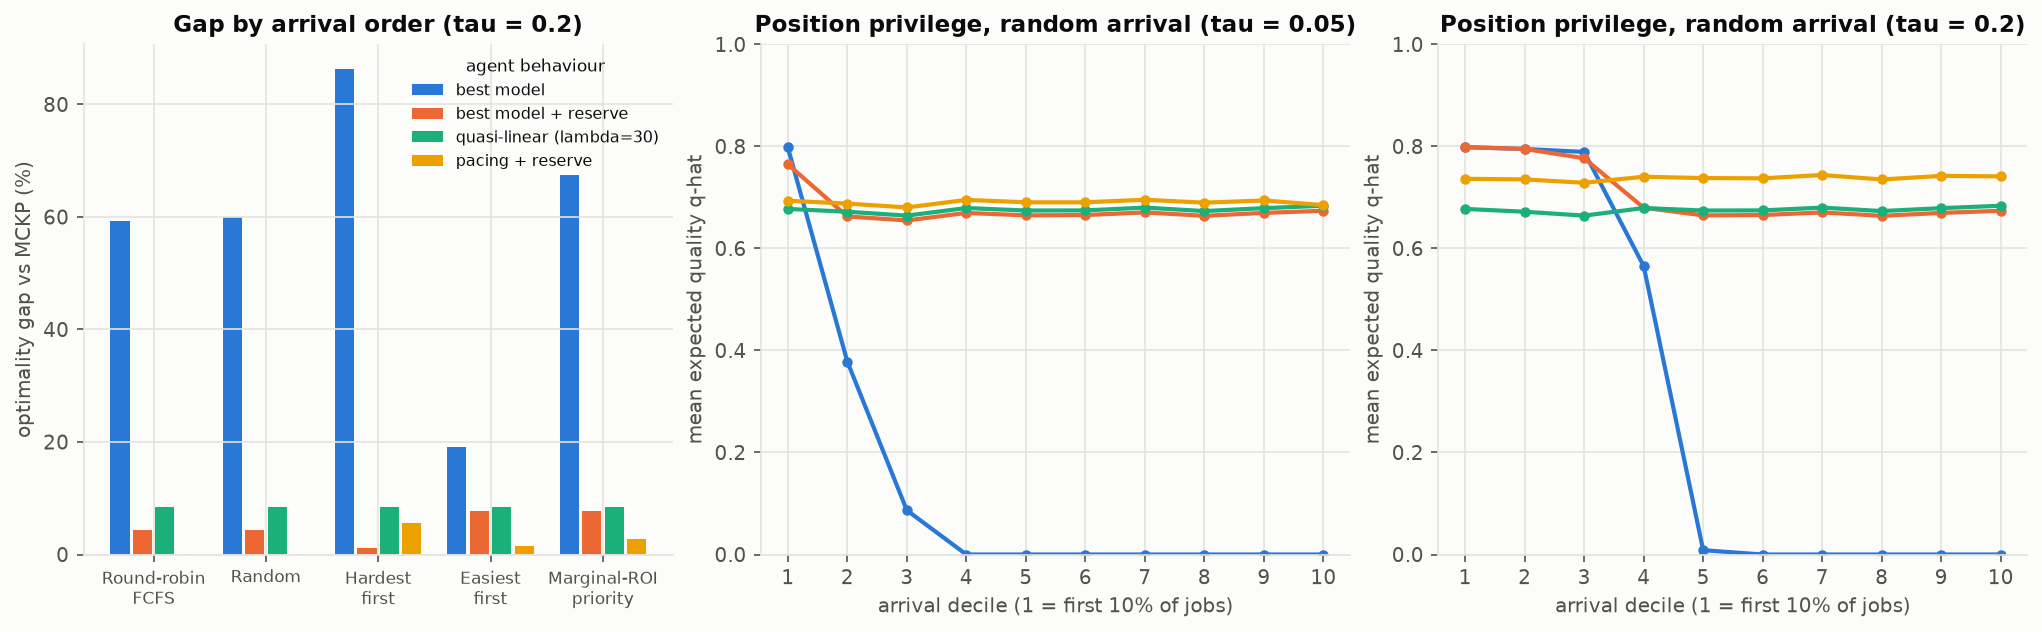

In [7]:
display(Image('experiments/figures/e03_arrival_ordering.png'))